# 19 · Learning curves: do more LLM labels let a richer model beat the hand-set X2?

Follow-up to notebook 18, whose learned weights did not beat the hand-set score on the A2 final set with 639 LLM-labelled A1 pairs. Here the *training-set size* varies, to see whether the curve is still rising and whether in-domain labels (the D50 batch from A2's train region) rise faster than A1's. **Exploratory**, under the user-authorised exception to D43/D51 (see `evaluation/a1_weights.py`); the A2 final set is scored on, never fitted on (D46).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from candidate_screener import reporting
from candidate_screener.evaluation import a1_weights as aw, final_set, indomain
from candidate_screener.matching import corpus

reporting.style(plt)
SEED = 0

frame = final_set.load(); lab = indomain.labels(frame)
a2 = (corpus.a2_pairs(text_variant="v2").set_index("pair_id").loc[lab.index].reset_index())
llm = aw.llm_labels()
matched = corpus.a1_pairs("test").drop_duplicates("pair_id").set_index("pair_id", drop=False).loc[llm.index]   # the 639 LLM-labelled pairs
print(f"A2 final {len(a2)} pairs | A1 LLM-labelled {len(llm)} pairs over {matched.jd_id.nunique()} JDs, Fit rate {llm.mean():.2f}")

A2 final 600 pairs | A1 LLM-labelled 639 pairs over 100 JDs, Fit rate 0.13


In [2]:
model = aw.build_scorer()
X_a2e = aw.features(model, a2).join(aw.extra_features(model, a2))
X_matche = aw.features(model, matched).join(aw.extra_features(model, matched))
scores = {"hand-set X2": aw.linear_score(X_a2e, aw.HAND_WEIGHTS)}
print(X_a2e.shape, X_matche.shape)

(600, 11) (639, 11)


## Part 3 · Learning curve: do more LLM-labelled A1 JDs keep helping?

**Registered before running** (rule 8; exploratory under the D43/D51 exception):

- **Data.** The 639 LLM-labelled A1 pairs (100 JDs). Training sets are random JD subsets of 10, 25, 50 and 70 JDs; each repetition holds out 30 JDs as an A1 test set. 20 repetitions.
- **Learners.** Logistic on the base 4 features; logistic on all 11; gradient boosting (depth 2, 100 trees) on all 11.
- **Curve is "still rising"** for a learner if mean A2 per-JD AUC at 70 JDs exceeds that at 25 JDs by more than 0.01.
- **A learner "beats hand-set X2"** if, trained on all 100 JDs, its paired delta on A2 has a total CI above 0 and positive generic and targeted deltas (the Part 1 bar). Three learners, so a single nominal pass is weak evidence.
- Each curve is also read against the hand-set X2 on the same A1 held-out JDs.

In [3]:
rng = np.random.default_rng(SEED)
jd_m = matched.jd_id; jds = np.array(sorted(jd_m.unique()))
SIZES, REPS = [10, 25, 50, 70], 20
rows = []
for rep in range(REPS):
    test_jds = rng.choice(jds, 30, replace=False); pool = np.setdiff1d(jds, test_jds)
    te = X_matche.index[jd_m.loc[X_matche.index].isin(test_jds)]
    hand_a1 = aw.mean_jd_auc(aw.linear_score(X_matche.loc[te], aw.HAND_WEIGHTS), llm, jd_m)[0]
    for n in SIZES:
        tr = X_matche.index[jd_m.loc[X_matche.index].isin(rng.choice(pool, n, replace=False))]
        if llm.loc[tr].nunique() < 2: continue
        for name, (kind, cols) in aw.LEARNERS.items():
            f = aw.fit_learner(kind, cols, X_matche.loc[tr], llm)
            rows.append({"learner": name, "train JDs": n, "rep": rep,
                         "A2 AUC": aw.mean_jd_auc(f(X_a2e).set_axis(a2.pair_id), lab.y, lab.jd_id)[0],
                         "A1 held-out AUC": aw.mean_jd_auc(f(X_matche.loc[te]), llm, jd_m)[0], "hand A1": hand_a1})
curve = pd.DataFrame(rows)
hand_a2 = aw.mean_jd_auc(scores["hand-set X2"].set_axis(a2.pair_id), lab.y, lab.jd_id)[0]
tab = curve.groupby(["learner", "train JDs"])[["A2 AUC", "A1 held-out AUC", "hand A1"]].mean().unstack("train JDs")
print(f"hand-set X2 on A2: {hand_a2:.3f}")
tab.round(3)

hand-set X2 on A2: 0.850


A2 AUC                      A1 held-out AUC                \
train JDs             10     25     50     70              10     25     50   
learner                                                                       
boosting all (11)  0.773  0.817  0.837  0.846           0.806  0.884  0.887   
logistic all (11)  0.795  0.824  0.838  0.842           0.870  0.901  0.915   
logistic base (4)  0.843  0.845  0.852  0.854           0.891  0.896  0.896   

                         hand A1                       
train JDs             70      10     25     50     70  
learner                                                
boosting all (11)  0.888   0.869  0.867  0.867  0.867  
logistic all (11)  0.931   0.869  0.867  0.867  0.867  
logistic base (4)  0.898   0.869  0.867  0.867  0.867

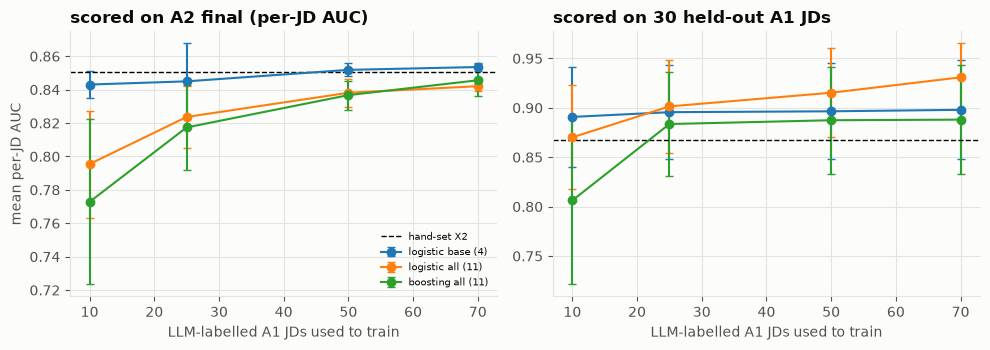

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
for ax, col, ref, title in [(axes[0], "A2 AUC", hand_a2, "scored on A2 final (per-JD AUC)"),
                            (axes[1], "A1 held-out AUC", curve["hand A1"].mean(), "scored on 30 held-out A1 JDs")]:
    for name in aw.LEARNERS:
        g = curve[curve.learner == name].groupby("train JDs")[col]
        ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=3, label=name)
    ax.axhline(ref, color="k", ls="--", lw=1, label="hand-set X2"); ax.set_title(title); ax.set_xlabel("LLM-labelled A1 JDs used to train")
axes[0].set_ylabel("mean per-JD AUC"); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

### Registered checks

In [5]:
rise = (curve[curve["train JDs"] == 70].groupby("learner")["A2 AUC"].mean() - curve[curve["train JDs"] == 25].groupby("learner")["A2 AUC"].mean())
final = {}
for name, (kind, cols) in aw.LEARNERS.items():
    f = aw.fit_learner(kind, cols, X_matche, llm)
    final[name] = f(X_a2e).set_axis(a2.pair_id)
rows = []
for name, s in final.items():
    d = {sc: indomain.paired_delta(s, scores["hand-set X2"], lab, a2, "auc", sc, "all", SEED) for sc in final_set.SCOPES}
    rows.append({"learner": name, "rise 25→70 JDs": rise[name], "still rising": bool(rise[name] > 0.01),
                 "Δ total vs hand": d["total"]["delta"], "CI": d["total"]["ci"],
                 "Δ generic": d["generic"]["delta"], "Δ targeted": d["targeted"]["delta"],
                 "bar met": bool(d["total"]["ci"][0] > 0 and d["generic"]["delta"] > 0 and d["targeted"]["delta"] > 0)})
pd.DataFrame(rows).round(4)

,learner,rise 25→70 JDs,still rising,Δ total vs hand,CI,Δ generic,Δ targeted,bar met
0,logistic base (4),0.0086,False,0.0058,"[-0.008626, 0.021007]",0.0080,0.0016,False
1,logistic all (11),0.0184,True,-0.0038,"[-0.029589, 0.021623]",0.0066,-0.0241,False
2,boosting all (11),0.0282,True,-0.0009,"[-0.023983, 0.022189]",-0.0007,-0.0012,False


## Part 4 · The same curve with LLM labels from A2's own train region (D50 batch)

**Registered before running** (rule 8; exploratory). The D50 batch is 1,000 pairs over 100 A2-train JDs, labelled by the final-set annotator (`claude-haiku-4-5`, instrument `5d986c82`, run 11), none from the final set or the eval region. Fit = Good ∪ Potential. D51 permits training a reranker on these scores and nothing else, so this use of them for a logistic regression and boosting is a further exception, like Part 1, and needs a decision-log entry before it is relied on.

- Same protocol as Part 3: JD subsets of 10, 25, 50 and 70; 30 held-out JDs per repetition; 20 repetitions; the same three learners.
- **In-domain labels help more** if, for some learner, the A2 rise from 25 to 70 JDs exceeds the Part 3 rise (A1 labels) by more than 0.01.
- **Beats hand-set X2:** the Part 3 bar, trained on all 100 D50 JDs.
- Differences to keep in mind: D50 pairs are 80% same-keyword (within-family) and 61% Fit, while the 639 A1 pairs are 13% Fit; D50 has 1,000 pairs, A1 has 639.

In [6]:
d50, y50 = aw.d50_pairs()
X50 = aw.features(model, d50).join(aw.extra_features(model, d50))
jd50 = d50.jd_id
print(f"{len(d50)} pairs, {jd50.nunique()} JDs, Fit rate {y50.mean():.2f}")
curve50 = aw.learning_curve(X50, y50, jd50, X_a2e, lab.y, lab.jd_id, SIZES, REPS, seed=SEED)
tab50 = curve50.groupby(["learner", "train JDs"])[["A2 AUC", "held-out AUC", "hand held-out"]].mean().unstack("train JDs")
print(f"hand-set X2 on A2: {hand_a2:.3f}")
tab50.round(3)

1000 pairs, 100 JDs, Fit rate 0.61


hand-set X2 on A2: 0.850


A2 AUC                      held-out AUC                \
train JDs             10     25     50     70           10     25     50   
learner                                                                    
boosting all (11)  0.810  0.828  0.844  0.845        0.829  0.847  0.847   
logistic all (11)  0.817  0.832  0.838  0.842        0.840  0.855  0.856   
logistic base (4)  0.847  0.844  0.848  0.848        0.858  0.861  0.862   

                         hand held-out                       
train JDs             70            10     25     50     70  
learner                                                      
boosting all (11)  0.849         0.861  0.861  0.861  0.861  
logistic all (11)  0.854         0.861  0.861  0.861  0.861  
logistic base (4)  0.863         0.861  0.861  0.861  0.861

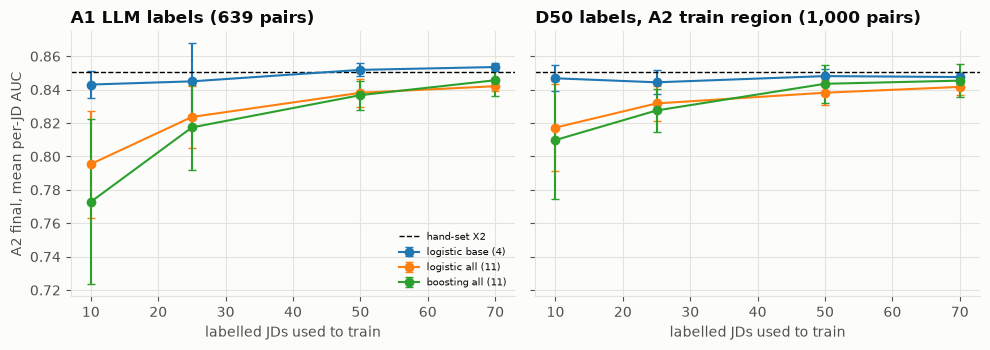

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True, sharey=True)
for ax, cv_, title in [(axes[0], curve.rename(columns={"A1 held-out AUC": "held-out AUC"}), "A1 LLM labels (639 pairs)"),
                       (axes[1], curve50, "D50 labels, A2 train region (1,000 pairs)")]:
    for name in aw.LEARNERS:
        g = cv_[cv_.learner == name].groupby("train JDs")["A2 AUC"]
        ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=3, label=name)
    ax.axhline(hand_a2, color="k", ls="--", lw=1, label="hand-set X2"); ax.set_title(title); ax.set_xlabel("labelled JDs used to train")
axes[0].set_ylabel("A2 final, mean per-JD AUC"); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

### Registered checks (Part 4)

In [8]:
def rise_of(c):
    g = c.groupby(["learner", "train JDs"])["A2 AUC"].mean()
    return g.xs(70, level=1) - g.xs(25, level=1)
r_a1, r_d50 = rise_of(curve), rise_of(curve50)
rows = []
for name, (kind, cols) in aw.LEARNERS.items():
    s = aw.fit_learner(kind, cols, X50, y50)(X_a2e)
    d = {sc: indomain.paired_delta(s, scores["hand-set X2"], lab, a2, "auc", sc, "all", SEED) for sc in final_set.SCOPES}
    rows.append({"learner": name, "rise 25→70 (A1 labels)": r_a1[name], "rise 25→70 (D50)": r_d50[name],
                 "D50 steeper": bool(r_d50[name] - r_a1[name] > 0.01),
                 "Δ total vs hand": d["total"]["delta"], "CI": d["total"]["ci"],
                 "Δ generic": d["generic"]["delta"], "Δ targeted": d["targeted"]["delta"],
                 "bar met": bool(d["total"]["ci"][0] > 0 and d["generic"]["delta"] > 0 and d["targeted"]["delta"] > 0)})
pd.DataFrame(rows).round(4)

,learner,rise 25→70 (A1 labels),rise 25→70 (D50),D50 steeper,Δ total vs hand,CI,Δ generic,Δ targeted,bar met
0,logistic base (4),0.0086,0.0032,False,-0.0038,"[-0.013839, 0.005997]",-0.0040,-0.0033,False
1,logistic all (11),0.0184,0.0099,False,-0.0101,"[-0.029095, 0.008199]",-0.0025,-0.0249,False
2,boosting all (11),0.0282,0.0179,False,-0.0044,"[-0.038063, 0.027823]",0.0086,-0.0298,False
